<a href="https://colab.research.google.com/github/tevfikaytekin/recommender_systems_course/blob/main/mf_pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Matrix Factorization with PyTorch

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, mean_absolute_error

In [4]:
#from google.colab import drive
#drive.mount('/content/drive')

### Download MovieLens 1M Dataset

We will download the MovieLens 1M dataset from the GroupLens website. This dataset contains 1 million ratings from 6,040 users on 3,706 movies. The main file we will use is `ratings.dat`

In [2]:
import os
import zipfile


# URL for MovieLens 1M dataset
# Download MovieLens 1M dataset using wget to bypass SSL issues
url = 'https://files.grouplens.org/datasets/movielens/ml-1m.zip'
download_path = 'ml-1m.zip'

if not os.path.exists(download_path):
    print("Downloading MovieLens 1M dataset...")
    os.system(f'wget --no-check-certificate {url}')
    with zipfile.ZipFile(download_path, 'r') as zip_ref:
        zip_ref.extractall('.')
    print("Download and extraction complete.")

print("Dataset setup complete. 'ratings.dat' is available in the 'ml-1m' directory.")

Download and extraction complete.
Dataset setup complete. 'ratings.dat' is available in the 'ml-1m' directory.


In [5]:
# Load MovieLens dataset directly from 'ratings.dat' using '::' separator
# https://grouplens.org/datasets/movielens/1m/
data = pd.read_csv("ml-1m/ratings.dat", sep='::', engine='python', names=['userId', 'movieId', 'rating', 'timestamp'])


print(data.shape)
data.head()

(1000209, 4)


,userId,movieId,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


In [6]:
# Map user and movie IDs to unique consecutive indices starting from 0.
# This is needed because embedding layer indexes start from 0
user_ids = data['userId'].unique()
movie_ids = data['movieId'].unique()

user_mapping = {user_id: idx for idx, user_id in enumerate(user_ids)}
movie_mapping = {movie_id: idx for idx, movie_id in enumerate(movie_ids)}

data['userId'] = data['userId'].map(user_mapping)
data['movieId'] = data['movieId'].map(movie_mapping)

num_users = len(user_ids)
num_movies = len(movie_ids)

In [33]:
data.head()

,userId,movieId,rating,timestamp
0,0,0,5,978300760
1,0,1,3,978302109
2,0,2,3,978301968
3,0,3,4,978300275
4,0,4,5,978824291


Standard Matrix Factorization Model

In [7]:
import torch
import torch.nn as nn

class StandardMatrixFactorizationModel(nn.Module):
    def __init__(self, num_users, num_movies, embedding_size=5, l2_lambda=0.01, use_bias=True, global_mean=3.5):
        super(StandardMatrixFactorizationModel, self).__init__()
        self.user_embedding = nn.Embedding(num_users, embedding_size)
        self.movie_embedding = nn.Embedding(num_movies, embedding_size)

        nn.init.normal_(self.user_embedding.weight, std=0.1)
        nn.init.normal_(self.movie_embedding.weight, std=0.1)



        self.use_bias = use_bias

        if self.use_bias:
            # Global mean bias initialized dynamically
            self.global_bias = nn.Parameter(torch.tensor(global_mean, dtype=torch.float32))

            # User bias: One bias term per user
            self.user_bias = nn.Embedding(num_users, 1)
            nn.init.constant_(self.user_bias.weight, 0)  # Initialize biases to zero

            # Item bias: One bias term per item
            self.item_bias = nn.Embedding(num_movies, 1)
            nn.init.constant_(self.item_bias.weight, 0)  # Initialize biases to zero

        # Regularization parameter
        self.l2_lambda = l2_lambda # Initialized l2_lambda

    def forward(self, X):
        n = X.shape[0]
        #prediction = torch.zeros((n), dtype=torch.float)

        # forward function takes the indices of some users and movies and make
        # prediction by find the dot products of the corresponding users and movies
        user_embedding = self.user_embedding(X[:,0])
        movie_embedding = self.movie_embedding(X[:,1])
        # below line calculates the dot product between embedding vectors
        dot_product = torch.sum(user_embedding * movie_embedding, dim=1)

        prediction = dot_product

        if self.use_bias:
            # Add biases
            user_b = self.user_bias(X[:,0]).squeeze()
            item_b = self.item_bias(X[:,1]).squeeze()
            prediction = self.global_bias + user_b + item_b + dot_product

        return prediction

    def get_regularization_loss(self):
        # L2 regularization on user and movie embedding weights
        # We sum the squared L2 norms of the embedding weights
        l2_reg = self.l2_lambda * (
            torch.norm(self.user_embedding.weight, p=2)**2 +
            torch.norm(self.movie_embedding.weight, p=2)**2
        )
        return l2_reg


Bias Only Model

In [8]:
class BiasOnlyModel(nn.Module):
    def __init__(self, num_users, num_movies):
        super(BiasOnlyModel, self).__init__()

        # Global mean bias
        self.global_bias = nn.Parameter(torch.tensor(0.0))

        # User bias: One bias term per user
        self.user_bias = nn.Embedding(num_users, 1)
        nn.init.constant_(self.user_bias.weight, 0)  # Initialize biases to zero

        # Item bias: One bias term per item
        self.item_bias = nn.Embedding(num_movies, 1)
        nn.init.constant_(self.item_bias.weight, 0)  # Initialize biases to zero

    def forward(self, X):
        user_b = self.user_bias(X[:,0]).squeeze()
        item_b = self.item_bias(X[:,1]).squeeze()
        prediction = self.global_bias + user_b + item_b

        return prediction

Model training function without using DataLoader

In [9]:
def train_model(model, data, optimizer, num_epochs = 100, batch_size = 64, criterion = nn.MSELoss()):

    total_loss = 0.0
    train_error = []
    n_samples = len(data)

    # Determine if GPU is available
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    # Move model to the GPU
    model.to(device)

    # Note1: In order to test the effectives of mini-batching or stochastic gradient descent,
    # you can try to increase batch_size up to n_samples. In that case the execution time of
    # each epoch will begin to decrease, however, since updates are done after each batch,
    # there will be a less number of updates in each epoch which will slow down convergence. On the other hand,
    # if batch_size is smaller (such as 32) then there will be n_samples/batch_size
    # updates in each epoch. This type of gradient descent is called mini-batch or stochastic gradient descent.

    # Note2: When batch_size = n_samples this code will run almost as fast as a C++ code.
    # However, if you decrease batch size the code will become slower compared to a C++ code
    # due to the overheads of the torch autograd framework. In the extreme if you set batch_size = 1
    # this speed difference will be significant.

    # Move the entire data to the GPU once
    X = torch.tensor(data[['userId', 'movieId']].values).to(device)
    y = torch.tensor(data['rating'].values.astype(np.float32)).to(device)

    import time
    start = time.time()

    model.train()
    for epoch in tqdm(range(num_epochs)):
        permutation = torch.randperm(n_samples)
        squared_errors = []

        for i in range(0, n_samples, batch_size):
            indices = permutation[i:i+batch_size]
            batch_X, batch_y = X[indices], y[indices]

            predictions = model(batch_X)

            loss = criterion(predictions, batch_y)

            # Add regularization loss if the model has a get_regularization_loss method
            if hasattr(model, 'get_regularization_loss'):
                reg_loss = model.get_regularization_loss()
                loss += reg_loss

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            squared_errors.extend(((predictions - batch_y)**2).tolist())

        if epoch % 1 == 0:
            train_error.append(np.sqrt(np.mean(squared_errors)))

    end = time.time()
    print("Elapsed time:", end - start)
    # Plot training errors
    plt.figure(figsize=(6, 3))
    plt.plot(train_error, label="Training RMSE")
    plt.xlabel("Epoch")
    plt.ylabel("Root Mean Squared Error (RMSE)")
    plt.title("Training Errors over Epochs")
    plt.ylim(0, 5)  # Set y-range from 0 to 5

    plt.legend()
    plt.grid()
    plt.show()

Model evaluation

In [10]:
def evaluate_model(model, test_data, criterion = nn.MSELoss()):
    X_test = torch.tensor(test_data[['userId', 'movieId']].values)
    y_test = torch.tensor(test_data['rating'].values.astype(np.float32))

    # Determine if GPU is available
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)
    X_test = X_test.to(device)
    y_test = y_test.to(device)

    model.eval()
    test_loss = 0.0
    with torch.no_grad():
        predictions = model(X_test)
        test_loss = criterion(predictions, y_test)

    print(model.__class__.__name__)
    #print(f"Test Loss: {test_loss / len(X_test)}")
    print(f"Test MAE: {mean_absolute_error(y_test.cpu(), predictions.cpu())}")
    print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test.cpu(), predictions.cpu()))}")

### Some Experiments


Following Experiments are done with ml-latest-small/ratings.csv file

What happens when embedding_size = 1? As you can see in the plot below, even with embedding_size = 1 some learning occurs, however, after some number of iterations (around 5), there is no further improvement. Why? (Note that we are not using any regularization and bias terms)

In [11]:
from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(data, test_size=0.1)

# Calculate exact global mean of ratings from the training data
exact_global_mean = train_data['rating'].mean()
print(f"Exact global mean of training ratings: {exact_global_mean:.4f}")


Exact global mean of training ratings: 3.5812


Using device: cuda


100%|██████████| 20/20 [00:07<00:00,  2.84it/s]

Elapsed time: 7.039653539657593


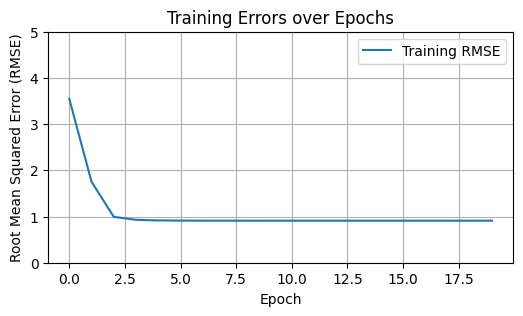

In [12]:
model = StandardMatrixFactorizationModel(num_users, num_movies, embedding_size=1, l2_lambda=0, use_bias=False)
batch_size = 8192
optimizer = optim.Adam(model.parameters(), lr=0.01)
train_model(model, train_data, optimizer = optimizer, num_epochs=20, batch_size=batch_size)

In [13]:
evaluate_model(model, test_data)

StandardMatrixFactorizationModel
Test MAE: 0.7222674723814109
Test RMSE: 0.9117792069081144


If we set embedding size = 10, we see that learning continues after iteration 5. However, even though we have a better training error, test error is worse? Why?

Using device: cuda


100%|██████████| 20/20 [00:06<00:00,  3.20it/s]

Elapsed time: 6.253430128097534


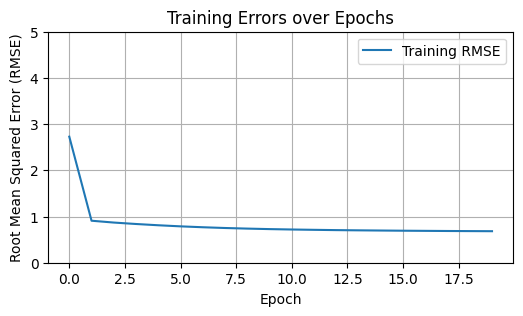

In [14]:
model = StandardMatrixFactorizationModel(num_users, num_movies, embedding_size=32, l2_lambda=0, use_bias=False)
batch_size = 8192
optimizer = optim.Adam(model.parameters(), lr=0.01)
train_model(model, train_data, optimizer = optimizer, num_epochs=20, batch_size=batch_size)

In [15]:
evaluate_model(model, test_data)

StandardMatrixFactorizationModel
Test MAE: 0.7430817712519937
Test RMSE: 0.9602735573570182


Let us add some regularization

Using device: cuda


100%|██████████| 20/20 [00:06<00:00,  3.16it/s]

Elapsed time: 6.330508708953857


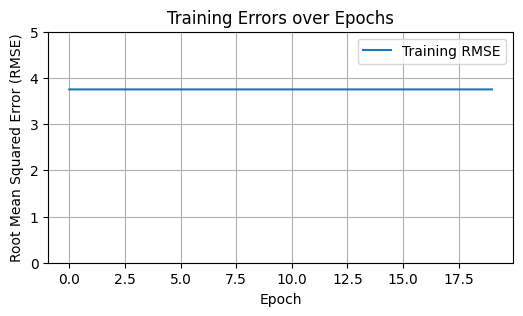

In [16]:
model = StandardMatrixFactorizationModel(num_users, num_movies, embedding_size=32, l2_lambda=0.01, use_bias=False)
batch_size = 8192
optimizer = optim.Adam(model.parameters(), lr=0.01)
train_model(model, train_data, optimizer = optimizer, num_epochs=20, batch_size=batch_size)

In [17]:
evaluate_model(model, test_data)

StandardMatrixFactorizationModel
Test MAE: 3.5852670939159967
Test RMSE: 3.754093821920409


### Why does the model fail to learn with `l2_lambda=0.01`?

As you can see from the flat training curve and the high test error, the model completely fails to learn when `l2_lambda=0.01`.

This happens because the regularization parameter is too large. When `l2_lambda` is set too high, the L2 penalty dominates the total loss function. The optimizer focuses almost entirely on pushing the embedding weights towards zero (to minimize the regularization loss) rather than minimizing the actual prediction error (MSE).

This is a classic case of **underfitting** due to excessive regularization. For matrix factorization on this dataset, typical values for the L2 regularization constant are much smaller, often in the range of $10^{-4}$ to $10^{-6}$, allowing the model to learn meaningful representations while just slightly penalizing overly large weights.

Now let us try `l2_lambda=0.00001`?

Using device: cuda


100%|██████████| 20/20 [00:06<00:00,  3.19it/s]

Elapsed time: 6.2706990242004395


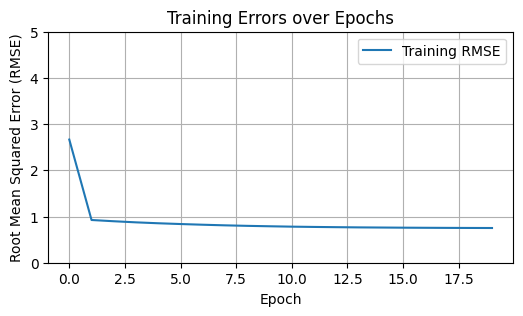

In [18]:
model = StandardMatrixFactorizationModel(num_users, num_movies, embedding_size=32, l2_lambda=0.00001, use_bias=False)
batch_size = 8192
optimizer = optim.Adam(model.parameters(), lr=0.01)
train_model(model, train_data, optimizer = optimizer, num_epochs=20, batch_size=batch_size)

In [19]:
evaluate_model(model, test_data)

StandardMatrixFactorizationModel
Test MAE: 0.6915701158842412
Test RMSE: 0.8817342326927495


Now, let us also include the bias terms.

Using device: cuda


100%|██████████| 20/20 [00:07<00:00,  2.64it/s]

Elapsed time: 7.570696115493774


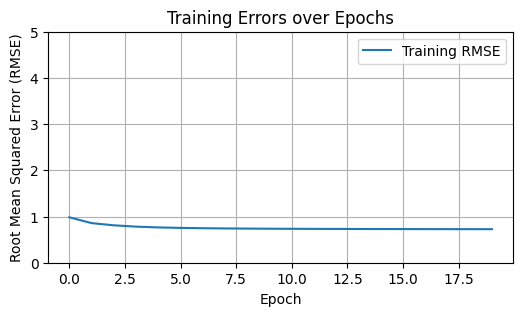

In [20]:
import torch.optim as optim

model = StandardMatrixFactorizationModel(num_users, num_movies, embedding_size=32, l2_lambda=0.00001, use_bias=True, global_mean=exact_global_mean)
batch_size = 8192
optimizer = optim.Adam(model.parameters(), lr=0.01)
train_model(model, train_data, optimizer = optimizer, num_epochs=20, batch_size=batch_size)


In [21]:
evaluate_model(model, test_data)

StandardMatrixFactorizationModel
Test MAE: 0.6732740202033836
Test RMSE: 0.8607112461778436


Even using only the bias terms can give decent results

Using device: cuda


100%|██████████| 20/20 [00:05<00:00,  3.80it/s]

Elapsed time: 5.262378931045532


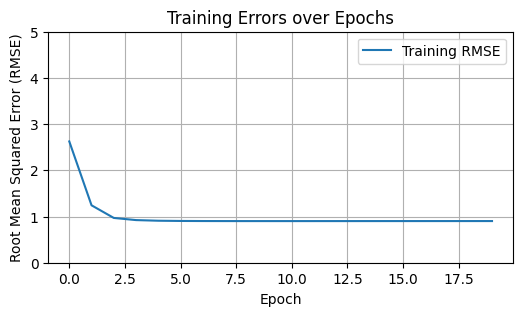

In [22]:
model = BiasOnlyModel(num_users, num_movies)
batch_size = 8192
optimizer = optim.Adam(model.parameters(), lr=0.01)
train_model(model, train_data, optimizer = optimizer, num_epochs=20, batch_size=batch_size)

In [23]:
evaluate_model(model, test_data)

BiasOnlyModel
Test MAE: 0.7155378218183225
Test RMSE: 0.9046774969269913


Now let us try to use the full training data in every epoch, but now we will need a larger number of epochs

Using device: cuda


100%|██████████| 200/200 [00:21<00:00,  9.24it/s]


Elapsed time: 21.657230615615845


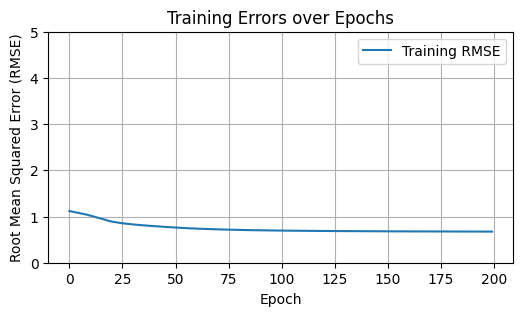

In [24]:
import torch.optim as optim

model = StandardMatrixFactorizationModel(num_users, num_movies, embedding_size=32, l2_lambda=0.00001, use_bias=True, global_mean=exact_global_mean)
batch_size = len(train_data)
optimizer = optim.Adam(model.parameters(), lr=0.01)
train_model(model, train_data, optimizer = optimizer, num_epochs=200, batch_size=batch_size)


In [25]:
evaluate_model(model, test_data)

StandardMatrixFactorizationModel
Test MAE: 0.6798012965792504
Test RMSE: 0.870027555570236


### Mini-Batch vs. Full-Batch Gradient Descent: A Summary

Based on our experiments, here is a comparison of the two approaches:

**Mini-Batch Gradient Descent (e.g., `batch_size = 8192`)**
* **Pros:**
  * **Faster Overall Convergence:** Because the weights are updated many times per epoch (e.g., 900,000 / 8192 $\approx$ 110 updates per epoch), the model reaches a low error much faster in terms of total training time.
  * **Memory Efficiency:** Only a small subset of the data needs to be loaded into the GPU memory at a time, which is essential for massive datasets.
  * **Better Generalization:** The noise introduced by approximating the gradient from a small batch can help the model escape sharp local minima and often leads to better generalization on unseen data.
* **Cons:**
  * **Framework Overhead:** Loading many small batches and calling the optimizer frequently introduces CPU/GPU communication overhead. If the batch size is too small (e.g., 64), this overhead dominates, making training painfully slow.

**Full-Batch Gradient Descent (e.g., `batch_size = len(train_data)`)**
* **Pros:**
  * **Zero Batching Overhead:** The entire dataset is pushed through the network at once, fully maximizing the GPU's parallel processing capabilities. Each epoch takes a fraction of a second.
  * **Stable Gradients:** Calculates the exact, true gradient of the entire dataset, leading to a very smooth and stable loss curve without noise.
* **Cons:**
  * **Extremely Slow Learning:** It only makes **one** weight update per epoch. Even though each epoch is lightning fast, it requires hundreds or thousands of epochs to converge, resulting in a much longer total training time.
  * **Memory Limits:** It requires the entire dataset, activations, and gradients to fit into the GPU memory at once, which is impossible for most modern deep learning tasks.

### With Dataloader

In [26]:
class MovieLensDataset(Dataset):
    def __init__(self, dataframe):
        # Determine device
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # Pre-convert the numpy arrays to PyTorch tensors AND move them to GPU
        self.data = torch.tensor(dataframe[['userId', 'movieId']].values, dtype=torch.long).to(device)
        self.ratings = torch.tensor(dataframe['rating'].values.astype(np.float32), dtype=torch.float32).to(device)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        # Simply return the slice of the pre-computed GPU tensor
        return self.data[idx], self.ratings[idx]


In [27]:
def train_model_dataloader(model, train_loader, test_loader, optimizer, num_epochs = 100, criterion = nn.MSELoss()):

    # Determine if GPU is available
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")

    # Move model to the GPU
    model.to(device)

    import time
    start = time.time()

    train_error = []
    model.train()
    for epoch in tqdm(range(num_epochs)):
        squared_errors_epoch = []
        for batch_X, batch_y in train_loader:
            # Move batch data to the GPU
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            predictions = model(batch_X)

            loss = criterion(predictions, batch_y.squeeze())

            # Add regularization loss if the model has a get_regularization_loss method
            if hasattr(model, 'get_regularization_loss'):
                reg_loss = model.get_regularization_loss()
                loss += reg_loss

            optimizer.zero_grad()

            loss.backward()
            optimizer.step()
            squared_errors_epoch.extend(((predictions - batch_y.squeeze())**2).tolist())

        if epoch % 1 == 0:
            train_error.append(np.sqrt(np.mean(squared_errors_epoch)))

    end = time.time()
    print("Elapsed time:", end - start)

    # Plot training errors
    plt.figure(figsize=(6, 3))
    plt.plot(train_error, label="Training RMSE")
    plt.xlabel("Epoch")
    plt.ylabel("Root Mean Squared Error (RMSE)")
    plt.title("Training Errors over Epochs")
    plt.ylim(0, 5)  # Set y-range from 0 to 5

    plt.legend()
    plt.grid()
    plt.show()

In [28]:
# Evaluate the model after training using the provided test_loader
def evaluate_model_dataloader(model, test_loader, criterion = nn.MSELoss()):
    model.eval()
    all_predictions = []
    all_targets = []
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)
    with torch.no_grad():
        for batch_X_test, batch_y_test in test_loader:
            batch_X_test = batch_X_test.to(device)
            batch_y_test = batch_y_test.to(device)

            predictions = model(batch_X_test)
            all_predictions.extend(predictions.cpu().tolist())
            all_targets.extend(batch_y_test.squeeze().cpu().tolist())

    print(model.__class__.__name__)
    print(f"Test MAE: {mean_absolute_error(all_targets, all_predictions)}")
    print(f"Test RMSE: {np.sqrt(mean_squared_error(all_targets, all_predictions))}")

In [29]:
# Split the data into training and testing sets
train_data, test_data = train_test_split(data, test_size=0.1)

# Initialize dataset and data loaders
train_dataset = MovieLensDataset(train_data)
test_dataset = MovieLensDataset(test_data)

n_samples = len(train_data)
batch_size = n_samples
# Note: Setting batch_size larger values will decrease the time of a single epoch but after
# a certain value it does not further decrease. In the extreme even if you set batch_size to n_samples
# the running time of a single epoch will still be significant. This is probably because of the overhead
# caused by dataset loader.
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

Using device: cuda


100%|██████████| 20/20 [02:26<00:00,  7.32s/it]

Elapsed time: 146.47847700119019


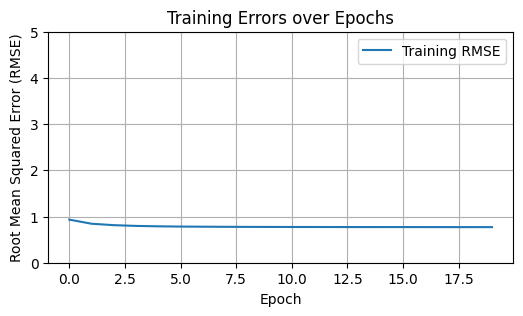

In [30]:
import torch.optim as optim
from torch.utils.data import DataLoader

# Recalculate exact global mean for the new split
exact_global_mean = train_data['rating'].mean()

# Initialize the model
model = StandardMatrixFactorizationModel(num_users, num_movies, embedding_size=32, l2_lambda=0.00001, use_bias=True, global_mean=exact_global_mean)

# Use a reasonable mini-batch size for training
batch_size = 2056
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Initialize optimizer
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Train using the dataloader
train_model_dataloader(model, train_loader, test_loader, optimizer=optimizer, num_epochs=20)


In [31]:
# Evaluate the model
evaluate_model_dataloader(model, test_loader)

StandardMatrixFactorizationModel
Test MAE: 0.6753781549744657
Test RMSE: 0.8639093733517149


### Why is PyTorch's DataLoader still slower than the manual loop?

Even after moving the tensors directly to the GPU in the `MovieLensDataset` initialization, you might notice that the `DataLoader` approach is still significantly slower than our original manual batching loop.

This performance gap comes down to **how the batches are formed**:

1. **Manual Vectorized Slicing:** In our first approach, we used `batch_X = X[indices]`. This is a **single, highly-optimized vectorized operation** that grabs the entire batch directly from the GPU memory at once.

2. **DataLoader Overhead:** By default, PyTorch's `DataLoader` constructs batches by calling the dataset's `__getitem__` method for **every single item** individually. For a batch size of 8,192, it makes 8,192 separate Python function calls, fetches each individual item, and then uses `torch.stack()` to combine them into a batch. This introduces a massive amount of Python loop overhead and memory allocation delays.

**Conclusion:**
PyTorch's `DataLoader` is primarily designed for large datasets that cannot fit into memory and need to be loaded incrementally from disk using multiple CPU workers (`num_workers > 0`). However, for datasets small enough to reside entirely in GPU memory, avoiding the DataLoader and using manual vectorized slicing is standard practice and drastically faster.

### Why DataLoader Excels for Images but Bottlenecks Tabular Data

The core of the performance difference lies in the **size of the data payload** returned by a single `__getitem__` call.

#### 1. Tabular/Recommender Data (Tiny Payload)
In our MovieLens dataset, a single `__getitem__` returns:
*   **Features:** A tensor of 2 integers (`userId`, `movieId`) -> 16 bytes (using 64-bit ints).
*   **Label:** A tensor of 1 float (`rating`) -> 4 bytes (using 32-bit floats).
*   **Total Size:** **~20 Bytes.**

Because the data is so incredibly small, fetching it takes almost zero time. Instead, 99% of the time is spent on PyTorch's overhead of making a Python function call and allocating memory for a new tiny tensor.

#### 2. Image Data (Massive Payload)
In a typical computer vision dataset (like ImageNet), a single `__getitem__` returns:
*   **Features:** An image tensor, usually shape `[3, 224, 224]` (Channels x Height x Width). If represented as 32-bit floats, this is `3 * 224 * 224 * 4 bytes` -> **~602 Kilobytes.**
*   **Label:** An integer class ID -> 8 bytes.
*   *(Note: Medical or high-res satellite images can easily be 10-50 Megabytes per item!)*

#### The Consequence
For images, a single `__getitem__` has to load a JPEG from the hard drive, decode it, apply random crops/rotations, and convert it to a float tensor. This is heavy computing. The tiny fraction of a millisecond PyTorch spends on Python overhead is completely negligible compared to the heavy lifting of image processing.

This is why `DataLoader` is built the way it is: it allows you to spin up multiple background CPU workers (`num_workers>0`) to process these heavy operations in parallel while the GPU trains on the previous batch. For tiny in-memory tabular datasets, this entire system just adds unnecessary drag.

## Exercises

1.  **Modify Learning Rate:** In the `StandardMatrixFactorizationModel` with `DataLoader` (cell `dcec771b`), change the learning rate of the Adam optimizer from `0.01` to `0.001` and train the model. Observe the training loss curve. Does it converge faster or slower? Is the final test RMSE better or worse? Why?

2.  **Change Optimizer:** PyTorch offers many different optimizers. Try replacing `optim.Adam` with `optim.SGD` (Stochastic Gradient Descent) in the dataloader training setup. Keep the learning rate at `0.01`. How does the performance compare to Adam? You might need to experiment with the `momentum` parameter in SGD to get good results.

3.  **Vary Embedding Size:** How does the `embedding_size` affect the model's performance and training time? Try training models with `embedding_size` set to `5`, `16`, `64`, and `128` (using the manual loop or dataloader, keeping other parameters constant like `l2_lambda=0.00001` and `use_bias=True`). Record the final Test RMSE for each. What is the optimal embedding size for this dataset?

4.  **Implement User-Based Regularization:** Currently, the L2 regularization is applied equally to both user and movie embeddings. Modify the `StandardMatrixFactorizationModel` to accept two separate regularization parameters: `user_l2_lambda` and `movie_l2_lambda`. Update the `get_regularization_loss` method to apply these separately. Train a model with `user_l2_lambda=0.0001` and `movie_l2_lambda=0.00001`. Does this improve the results?

## Solutions

Below are possible solutions and explanations for the exercises.

### Solution 1: Modify Learning Rate

If you decrease the learning rate to `0.001`:
*   **Convergence:** The training loss curve will decrease much more slowly. It might require more epochs to reach the same level of error as the `0.01` learning rate.
*   **Test RMSE:** The final test RMSE might be slightly better or about the same, provided you train for enough epochs. A smaller learning rate takes smaller steps, which can help the model settle into a slightly better, deeper local minimum without bouncing out, but it takes longer to get there. If it's worse, it might just need more epochs to converge.

### Solution 2: Change Optimizer

```python
# Using SGD instead of Adam
model_sgd = StandardMatrixFactorizationModel(num_users, num_movies, embedding_size=32, l2_lambda=0.00001, use_bias=True, global_mean=exact_global_mean)
optimizer_sgd = optim.SGD(model_sgd.parameters(), lr=0.01, momentum=0.9)
# Train the model...
```

*   **Observation:** SGD without momentum often converges much slower than Adam on this type of task. Adam adaptively changes the learning rate for each parameter, which is very helpful for sparse data like recommender systems. By adding momentum (e.g., `momentum=0.9`), SGD can perform better, but Adam usually provides a better out-of-the-box experience for Matrix Factorization.

### Solution 3: Vary Embedding Size

*   `embedding_size=5`: Very fast training, but might underfit (higher RMSE) because it cannot capture enough latent features.
*   `embedding_size=16`: Good balance. Often gives decent results quickly.
*   `embedding_size=32`: (Our baseline). Usually a solid choice for 1M dataset.
*   `embedding_size=64` or `128`: Takes longer to train per epoch. Might start to overfit the training data unless you increase the regularization (`l2_lambda`). The test RMSE might initially drop but then rise again if over-parameterized without enough regularization.

*Optimal size:* The "optimal" size is usually found via hyperparameter tuning (e.g., grid search), balancing model complexity against available data.

### Solution 4: Implement User-Based Regularization

```python
class EnhancedMatrixFactorizationModel(nn.Module):
    def __init__(self, num_users, num_movies, embedding_size=5, user_l2_lambda=0.01, movie_l2_lambda=0.01, use_bias=True, global_mean=3.5):
        super(EnhancedMatrixFactorizationModel, self).__init__()
        # ... (embedding definitions same as before) ...
        
        self.user_l2_lambda = user_l2_lambda
        self.movie_l2_lambda = movie_l2_lambda

    # ... (forward method same as before) ...

    def get_regularization_loss(self):
        user_reg = self.user_l2_lambda * torch.norm(self.user_embedding.weight, p=2)**2
        movie_reg = self.movie_l2_lambda * torch.norm(self.movie_embedding.weight, p=2)**2
        return user_reg + movie_reg
```
*   **Why do this?** Users and movies might have different noise levels. For example, some users rate everything 5 stars regardless of quality, while movie features might be more consistent. Regularizing them separately gives the model more flexibility to handle these differences.